In [1]:
import torch
from tqdm import tqdm
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats('svg', 'pdf')

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
torch.manual_seed(10)

In [4]:
Path("outputs").mkdir(parents=True, exist_ok=True)

In [5]:
x1 = [0.1,0.3,0.1,0.6,0.4,0.6,0.5,0.9,0.4,0.7]
x2 = [0.1,0.4,0.5,0.9,0.2,0.3,0.6,0.2,0.4,0.6]
x = torch.tensor(list(zip(x1, x2)), dtype=torch.float32).to(device)

In [6]:
y = torch.tensor([[1,0]]*5 + [[0,1]]*5, dtype=torch.float32).to(device)
y_labels = y[:,0:1].to(device)

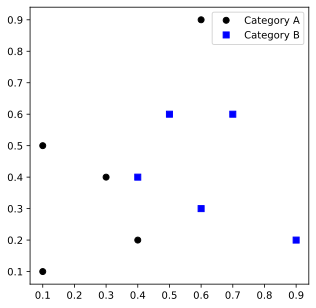

In [7]:
fig = plt.figure(figsize=(5,5))
plt.plot(x[y_labels[:,0]==1,0].cpu(), x[y_labels[:,0]==1,1].cpu(), 'ko', label='Category A')
plt.plot(x[y_labels[:,0]==0,0].cpu(), x[y_labels[:,0]==0,1].cpu(), 'bs', label='Category B')
plt.legend()
plt.savefig("outputs/input_data.png")
plt.show()

In [8]:
def init_layer(in_dim, out_dim):
    W = 0.5 * torch.randn(out_dim, in_dim).to(device)
    b = 0.5 * torch.randn(out_dim).to(device)
    return W, b

In [9]:
loss = 'mse' ## mse or ce

In [10]:
W1, b1 = init_layer(2,2)
W2, b2 = init_layer(2,3)

if loss=='mse':
    W3, b3 = init_layer(3,2)
elif loss=='ce':
    W3, b3 = init_layer(3,1)

In [11]:
def activate(X,W,b):
    return 1 / (1 + torch.exp(-(X @ W.T + b)))

In [12]:
def forward(X):
    a1 = activate(X, W1, b1)
    a2 = activate(a1, W2, b2)
    a3 = activate(a2, W3, b3)
    return a1, a2, a3

In [13]:
def cost(X,Y,Y_labels,C):
    _, _, a3 = forward(X)
    if C=='mse':
        costval = torch.mean(torch.sum((Y - a3)**2, dim=1))
    elif C=='ce':
        eps = 1e-7
        a3 = torch.clamp(a3, eps, 1 - eps) # for numerical stability
        costval = -torch.mean(Y_labels * torch.log(a3) + (1 - Y_labels) * torch.log(1 - a3))
    return costval

In [14]:
eta = 0.05
Niter = 1000000
savecost = torch.zeros(Niter,1, device=device)

In [15]:
pbar = tqdm(range(Niter))
for i in pbar:
    k = torch.randint(0, x.shape[0], (1,), device=device)
    val = x[k]
    a1, a2, a3 = forward(val)
    if loss=='mse':
        delta3 = a3*(1-a3)*(a3-y[k])
    elif loss=='ce':
        delta3 = a3-y_labels[k]
    delta2 = a2*(1-a2)*(delta3 @ W3)
    delta1 = a1*(1-a1)*(delta2 @ W2)

    W3 -= eta * (delta3.T @ a2)
    W2 -= eta * (delta2.T @ a1)
    W1 -= eta * (delta1.T @ val)

    b3 -= eta * delta3.squeeze(0)
    b2 -= eta * delta2.squeeze(0)
    b1 -= eta * delta1.squeeze(0)

    with torch.no_grad():
        savecost[i] = cost(x,y,y_labels,loss)
    pbar.set_postfix(cost=float(savecost[i]))

100%|██████████| 1000000/1000000 [34:11<00:00, 487.52it/s, cost=7.45e-5]


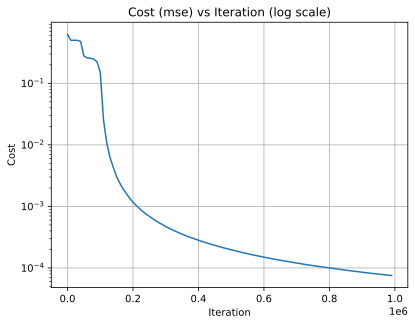

In [16]:
savecost = savecost.cpu().numpy()
indices = torch.arange(1, 1000001, 10000)
plt.semilogy(indices, savecost[indices - 1])
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title(f'Cost ({loss}) vs Iteration (log scale)')
plt.grid(True)
plt.savefig(f"outputs/{loss}_cost.png")
plt.show()

In [17]:
N = 500
xvals = torch.linspace(0, 1, N + 1)
yvals = torch.linspace(0, 1, N + 1)

Aval = torch.zeros((N + 1, N + 1))
Bval = torch.zeros((N + 1, N + 1))

X, Y = torch.meshgrid(xvals, yvals, indexing='xy')
XY = torch.stack([X.flatten(), Y.flatten()], dim=1)

for k1 in range(N + 1):
    xk = xvals[k1].to(device)
    for k2 in range(N + 1):
        yk = yvals[k2].to(device)
        xy = torch.tensor([xk, yk]).to(device)
        _, _, m3 = forward(xy)
        if loss=='mse':
            Aval[k2, k1] = m3[0]
            Bval[k2, k1] = m3[1]
        elif loss=='ce':
            Aval[k2, k1] = m3 if m3.ndim == 0 else m3[0]

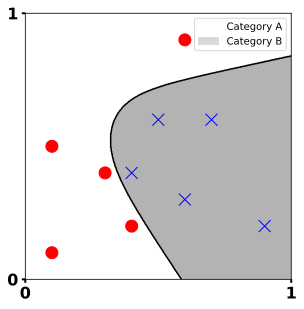

In [18]:
if loss=='mse':
    Mval = (Aval > Bval).numpy()

elif loss=='ce':
    threshold = 0.5
    Mval = (Aval > threshold).numpy()

plt.figure(3)
plt.clf()
ax = plt.subplot(1, 1, 1)
ax.imshow(Mval, extent=[0, 1, 0, 1], origin='lower', cmap=plt.cm.gray, alpha=0.3)
ax.contour(X, Y, Mval, levels=[0.5], colors='k')
ax.set_aspect('equal')

ax.plot(x1[:5], x2[:5], 'ro', markersize=12, linewidth=4)
ax.plot(x1[5:10], x2[5:10], 'bx', markersize=12, linewidth=4)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.tick_params(labelsize=16, width=2)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

ax.set_xlim([0, 1])
ax.set_ylim([0, 1])

patch_A = mpatches.Patch(color='white', label='Category A')
patch_B = mpatches.Patch(color='gray', alpha=0.3, label='Category B')
ax.legend(handles=[patch_A, patch_B], loc='upper right')

plt.savefig(f"outputs/{loss}_boundary.png")
plt.show()
